# Loan Default Prediction

UML501 Machine Learning project

Aabhas Khandelwal (1024030673), Joy Soni (1024030674)

We predict whether a loan applicant will default using the UCI German Credit dataset. We train five models (Logistic Regression, Decision Tree, Random Forest, XGBoost and LightGBM), and judge them on recall for defaulters, because approving someone who later defaults costs a bank more than turning away a good applicant.

In [1]:
!pip install -q -U ucimlrepo scikit-learn xgboost lightgbm
#uciml repo is for dataset imports,scikit provides ML models
#-q is quiet output 
# -U upgrades a package already installed


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo#download uci dataset by id
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer#apply preprocessing to different columns
from sklearn.impute import SimpleImputer#fill in blank values
from sklearn.preprocessing import StandardScaler, OneHotEncoder#scale values and turn categories into 0/1 column
from sklearn.pipeline import Pipeline#chain step of transformers so they fit together as one model
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, make_scorer,f1_score, confusion_matrix, ConfusionMatrixDisplay)

from sklearn.model_selection import GridSearchCV
from sklearn.metrics import roc_curve, roc_auc_score
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

os.makedirs("figures", exist_ok=True)

## 1. Load the data

we read it directly, otherwise we download the file from the UCI repository.The target is 1 = good and 2 = bad, so we turn it into 1 = default and 0 = no default.

In [3]:
cols = ["status_checking", "duration_months", "credit_history", "purpose", "credit_amount",
        "savings", "employment_since", "installment_rate", "personal_status_sex",
        "other_debtors", "residence_since", "property", "age", "other_installment_plans",
        "housing", "existing_credits", "job", "num_dependents", "telephone", "foreign_worker"] #as raw file has no header

if os.path.exists("data/german.data"):
    raw = pd.read_csv("data/german.data", sep=" ", header=None)
    X, target = raw.iloc[:, :20].copy(), raw.iloc[:, 20]
else:
    data = fetch_ucirepo(id=144)
    X, target = data.data.features.copy(), data.data.targets.iloc[:, 0]

X.columns = cols#rename column to cols
y = (target == 2).astype(int).rename("default")#rename column to default and put 1 if defualt and 0 if no default
print(X.shape, y.shape)

(1000, 20) (1000,)


In [4]:
X.head()

,status_checking,duration_months,credit_history,purpose,credit_amount,savings,employment_since,installment_rate,personal_status_sex,other_debtors,residence_since,property,age,other_installment_plans,housing,existing_credits,job,num_dependents,telephone,foreign_worker
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,4,A121,67,A143,A152,2,A173,1,A192,A201
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,2,A121,22,A143,A152,1,A173,1,A191,A201
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,3,A121,49,A143,A152,1,A172,2,A191,A201
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,4,A122,45,A143,A153,1,A173,2,A191,A201
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,4,A124,53,A143,A153,2,A173,2,A191,A201


## 2. Make the categories readable

The raw file stores categories as codes like A11 or A43. We map them to the meanings given in the UCI documentation (amounts are in Deutsche Mark). The model does not care about the names, but it makes the plots readable.

In [5]:
labels = {
    "status_checking": {"A11": "< 0 DM", "A12": "0 to 200 DM", "A13": ">= 200 DM", "A14": "no checking account"},
    "credit_history": {"A30": "no credits / all paid", "A31": "all paid at this bank",
                       "A32": "existing paid till now", "A33": "delays in the past",
                       "A34": "critical account"},
    "purpose": {"A40": "new car", "A41": "used car", "A42": "furniture", "A43": "radio/TV",
                "A44": "appliances", "A45": "repairs", "A46": "education", "A48": "retraining",
                "A49": "business", "A410": "other"},
    "savings": {"A61": "< 100 DM", "A62": "100 to 500 DM", "A63": "500 to 1000 DM",
                "A64": ">= 1000 DM", "A65": "unknown / none"},
    "employment_since": {"A71": "unemployed", "A72": "< 1 year", "A73": "1 to 4 years",
                         "A74": "4 to 7 years", "A75": ">= 7 years"},
    "personal_status_sex": {"A91": "male divorced", "A92": "female div/married", "A93": "male single",
                            "A94": "male married", "A95": "female single"},
    "other_debtors": {"A101": "none", "A102": "co-applicant", "A103": "guarantor"},
    "property": {"A121": "real estate", "A122": "savings/insurance", "A123": "car or other",
                 "A124": "unknown / none"},
    "other_installment_plans": {"A141": "bank", "A142": "stores", "A143": "none"},
    "housing": {"A151": "rent", "A152": "own", "A153": "for free"},
    "job": {"A171": "unskilled non-resident", "A172": "unskilled resident",
            "A173": "skilled employee", "A174": "management / self-employed"},
    "telephone": {"A191": "none", "A192": "yes"},
    "foreign_worker": {"A201": "yes", "A202": "no"},
}
#this is a dictionary of dictionary it maps a code like "A11" to its meaning like "<0 DM" DM is german currency

for col, mapping in labels.items():
    X[col] = X[col].map(mapping)#replace each code with its label

print("Unmapped values:", X.isnull().sum().sum())
X.head()

Unmapped values: 0


,status_checking,duration_months,credit_history,purpose,credit_amount,savings,employment_since,installment_rate,personal_status_sex,other_debtors,residence_since,property,age,other_installment_plans,housing,existing_credits,job,num_dependents,telephone,foreign_worker
0,< 0 DM,6,critical account,radio/TV,1169,unknown / none,>= 7 years,4,male single,none,4,real estate,67,none,own,2,skilled employee,1,yes,yes
1,0 to 200 DM,48,existing paid till now,radio/TV,5951,< 100 DM,1 to 4 years,2,female div/married,none,2,real estate,22,none,own,1,skilled employee,1,none,yes
2,no checking account,12,critical account,education,2096,< 100 DM,4 to 7 years,2,male single,none,3,real estate,49,none,own,1,unskilled resident,2,none,yes
3,< 0 DM,42,existing paid till now,furniture,7882,< 100 DM,4 to 7 years,2,male single,guarantor,4,savings/insurance,45,none,for free,1,skilled employee,2,none,yes
4,< 0 DM,24,delays in the past,new car,4870,< 100 DM,1 to 4 years,3,male single,none,4,unknown / none,53,none,for free,2,skilled employee,2,none,yes


## 3. Data cleaning

We check four things: blank cells, duplicate rows, missing information hidden inside categories, and outliers.

In [6]:
print("Blank cells:", X.isnull().sum().sum())
print("Duplicate rows:", X.duplicated().sum())

Blank cells: 0
Duplicate rows: 0


There are no blank cells, but some categories are really missing information. "unknown / none" for savings or property means the bank did not know. We check whether these rows behave differently before deciding what to do with them.

In [7]:
hidden = {"savings": "unknown / none", "property": "unknown / none"}
rows = {}
for col, val in hidden.items():
    mask = X[col] == val#all rows with the hidden value
    rows[f"{col} = {val}"] = {"Rows": mask.sum(),
                             "Default rate": round(y[mask].mean(), 3),
                             "Default rate (others)": round(y[~mask].mean(), 3)}
pd.DataFrame(rows).T.astype({"Rows": int})#build a table and transpose it

,Rows,Default rate,Default rate (others)
savings = unknown / none,183,0.175,0.328
property = unknown / none,154,0.435,0.275


Unknown savings default less than average and unknown property defaults more. So "unknown" carries signal. Filling it with the most common value would erase that, so we keep it as its own category and let one-hot encoding give it its own column.

In [8]:
num_cols = X.select_dtypes(include="number").columns#pick numeric classes
rows = {}
for col in num_cols:
    q1, q3 = X[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    mask = (X[col] < q1 - 1.5 * iqr) | (X[col] > q3 + 1.5 * iqr)#mark values that are outliers
    rows[col] = {"Unique values": X[col].nunique(), "Outliers (IQR)": mask.sum(),
                 "Default rate of outliers": round(y[mask].mean(), 3) if mask.any() else None}
print("Overall default rate:", y.mean())
pd.DataFrame(rows).T.astype({"Unique values": int, "Outliers (IQR)": int})#.T as dict builds table opposite

Overall default rate: 0.3


,Unique values,Outliers (IQR),Default rate of outliers
duration_months,33,70,0.571
credit_amount,921,72,0.542
installment_rate,4,0,NaN
residence_since,4,0,NaN
age,53,23,0.261
existing_credits,4,6,0.333
num_dependents,2,155,0.297


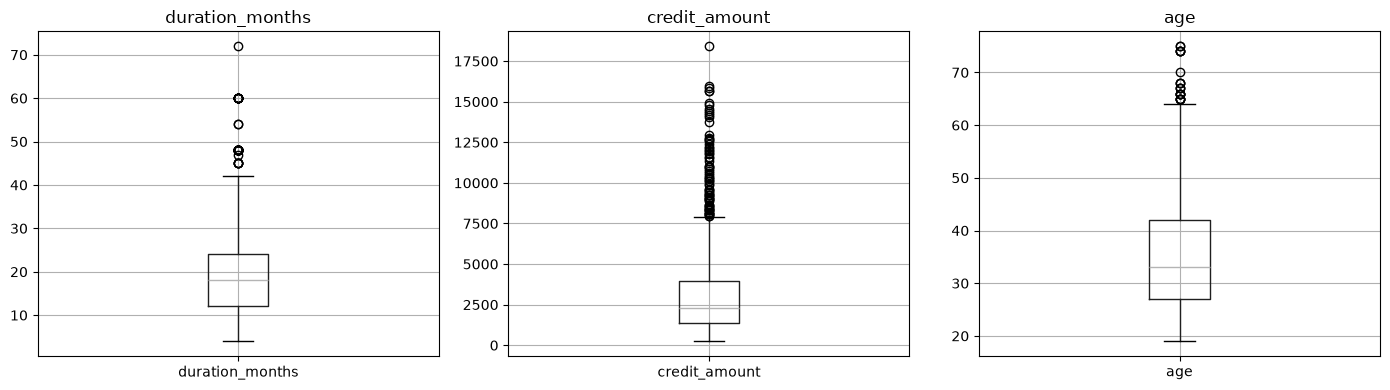

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["duration_months", "credit_amount", "age"]):
    X.boxplot(column=col, ax=ax)
    ax.set_title(col)
plt.tight_layout()#stop overlapping
plt.savefig("figures/outliers.png", dpi=150, bbox_inches="tight")
plt.show()

Long loans and large loans are outliers by the IQR rule, but they are real loans and they default at almost twice the normal rate. Removing them would throw away the riskiest applicants, so we keep them. Scaling handles the size difference. `num_dependents` only takes the values 1 and 2, so the IQR rule flags every 2 as an outlier since 1 has 845 people and 2 has 155 people this signals class imbalance

## 4. Explore the data

Missing values: 0
default
0    0.7
1    0.3
Name: proportion, dtype: float64


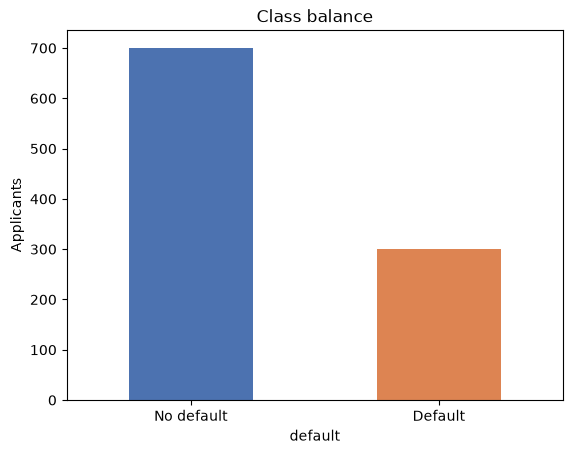

In [10]:
print("Missing values:", X.isnull().sum().sum())
print(y.value_counts(normalize=True))#print shares

y.map({0: "No default", 1: "Default"}).value_counts().plot(kind="bar", rot=0, color=["#4C72B0", "#DD8452"])
plt.title("Class balance")
plt.ylabel("Applicants")
plt.savefig("figures/class_balance.png", dpi=150, bbox_inches="tight")
plt.show()

Only 30% of applicants default. A model that always says "no default" would already be 70% accurate, which is why accuracy alone is a bad score here.

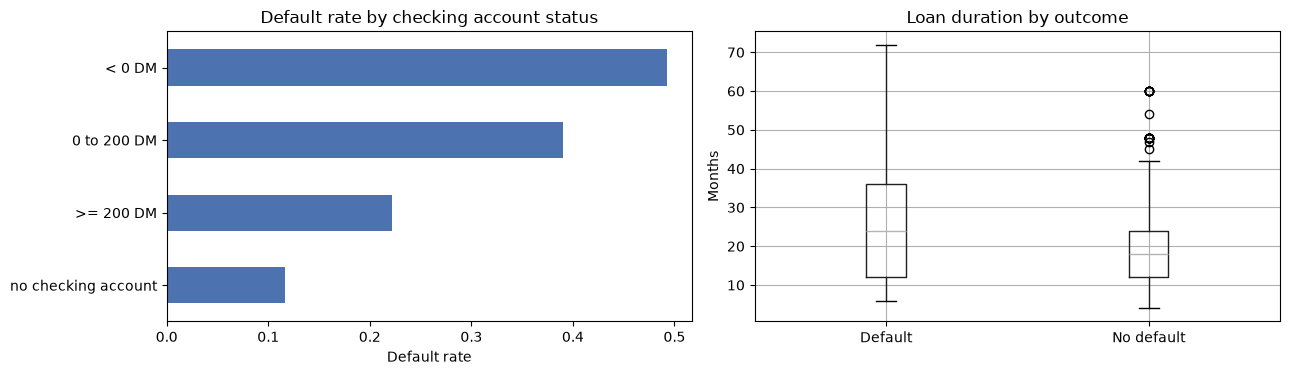

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

rate = y.groupby(X["status_checking"]).mean().sort_values()
rate.plot(kind="barh", ax=axes[0], color="#4C72B0")
axes[0].set_title("Default rate by checking account status")
axes[0].set_xlabel("Default rate")
axes[0].set_ylabel("")

X.assign(default=y.map({0: "No default", 1: "Default"})).boxplot(
    column="duration_months", by="default", ax=axes[1])
''' X.assign(default=...) adds a temporary label column without changing X. boxplot(column="duration_months", by="default") draws one box per outcome.'''
axes[1].set_title("Loan duration by outcome")
axes[1].set_xlabel("")
axes[1].set_ylabel("Months")
fig.suptitle("")

plt.tight_layout()
plt.savefig("figures/eda.png", dpi=150, bbox_inches="tight")
plt.show()

Applicants with a negative checking balance default far more often, and defaulters tend to take longer loans. So the features carry real signal.

## 5. Train/test split

`stratify=y` keeps the same 70/30 ratio in both sets.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)#stratify keeps same same 70/30 split of y
print("Train:", X_train.shape, "Test:", X_test.shape)
print("Train:", y_train.shape, "Test:", y_test.shape)

Train: (800, 20) Test: (200, 20)
Train: (800,) Test: (200,)


## 6. Preprocessing, models and metrics

Numeric columns are scaled and categorical columns are one-hot encoded. We also add an imputer in front of each (median for numbers, most common value for categories). This data has no blanks, so it changes nothing here, but a new applicant with a missing field would still get a prediction. All of these steps sit inside a `Pipeline`, so they are fitted on the training data only and the test set never leaks into training.

We compare five models: Logistic Regression (linear), a Decision Tree, Random Forest (many trees voting), and two gradient boosting models, XGBoost and LightGBM. Boosting builds trees one after another, and each new tree corrects the mistakes of the trees before it. XGBoost has no `class_weight` option, so for the balanced version we use `scale_pos_weight` = good / bad in the training set (560 / 240 = 2.33), which gives defaulters the same 2.3x weight.

For metrics, default is the positive class. Recall (also called sensitivity) is the share of real defaulters we catch. Specificity is the share of good applicants we correctly approve.

In [13]:
num_cols = X.select_dtypes(include="number").columns
cat_cols = X.select_dtypes(exclude="number").columns

def make_prep():#build preprocessing
    num = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])#Numeric steps: fill blanks with the median, then standardize: $z = \frac{x - \mu}{\sigma}$ ($\mu$ = mean, $\sigma$ = standard deviation, both from the training data).
    cat = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore"))])#Categorical steps: fill blanks with the most common value, then one-hot encode. handle_unknown="ignore" gives an all-zero row for a category the model never saw, instead of an error.
    return ColumnTransformer([("num", num, num_cols), ("cat", cat, cat_cols)])#apply different preprocessing to different column and then joins

spw = (y_train == 0).sum() / (y_train == 1).sum()  # 560 / 240 = 2.33, XGBoost's version of "balanced"

def make_models(class_weight=None):#class_weight sets how much a mistake on each class counts in the training loss
    models = {
        "Logistic Regression": LogisticRegression(max_iter=1000, class_weight=class_weight),#give enough iters to converge
        "Decision Tree": DecisionTreeClassifier(max_depth=5, class_weight=class_weight, random_state=42),
        "Random Forest": RandomForestClassifier(class_weight=class_weight, random_state=42),
        "XGBoost": XGBClassifier(scale_pos_weight=spw if class_weight == "balanced" else 1,
                                 eval_metric="logloss", random_state=42),#XGBoost has no class_weight, scale_pos_weight does the same job
        "LightGBM": LGBMClassifier(class_weight=class_weight, random_state=42, verbose=-1),
    }
    return {name: Pipeline([("prep", make_prep()), ("clf", clf)]) for name, clf in models.items()}
'''return this
{
    "Logistic Regression": Pipeline([
        ("prep", ColumnTransformer([("num", ..., num_cols), ("cat", ..., cat_cols)])),
        ("clf",  LogisticRegression(max_iter=1000, class_weight="balanced")),
    ]),
    "Decision Tree": Pipeline([
        ("prep", ColumnTransformer([...])),
        ("clf",  DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42)),
    ]),
    "Random Forest": Pipeline([
        ("prep", ColumnTransformer([...])),
        ("clf",  RandomForestClassifier(class_weight="balanced", random_state=42)),
    ]),
    "XGBoost": Pipeline([...]),
    "LightGBM": Pipeline([...]),
}
'''

def train(class_weight=None):
    return {name: pipe.fit(X_train, y_train) for name, pipe in make_models(class_weight).items()}#.fit returns pipelineand pipeline fit calls transform so no need to call explicitly

def metrics(models):
    rows = {}
    for name, m in models.items():
        pred = m.predict(X_test)
        rows[name] = {"Accuracy": accuracy_score(y_test, pred),
                      "Precision": precision_score(y_test, pred),
                      "Recall": recall_score(y_test, pred),
                      "Specificity": recall_score(y_test, pred, pos_label=0),
                      "F1": f1_score(y_test, pred)}
    return pd.DataFrame(rows).T.round(3)

def plot_confusion(models, path):
    fig, axes = plt.subplots(1, len(models), figsize=(5 * len(models), 4), squeeze=False)#squeeze keeps axes 2d so we can call axes[0]
    for ax, (name, m) in zip(axes[0], models.items()):
        cm = confusion_matrix(y_test, m.predict(X_test))
        ConfusionMatrixDisplay(cm, display_labels=["No default", "Default"]).plot(ax=ax, colorbar=False)#colorbar hides if set false
        ax.set_title(name)
    plt.tight_layout()
    plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()

## 7. Baseline models

In [14]:
baseline = train()
base_table = metrics(baseline)
base_table

,Accuracy,Precision,Recall,Specificity,F1
Logistic Regression,0.780,0.667,0.533,0.886,0.593
Decision Tree,0.645,0.420,0.483,0.714,0.450
Random Forest,0.780,0.735,0.417,0.936,0.532
XGBoost,0.755,0.608,0.517,0.857,0.559
LightGBM,0.730,0.565,0.433,0.857,0.491


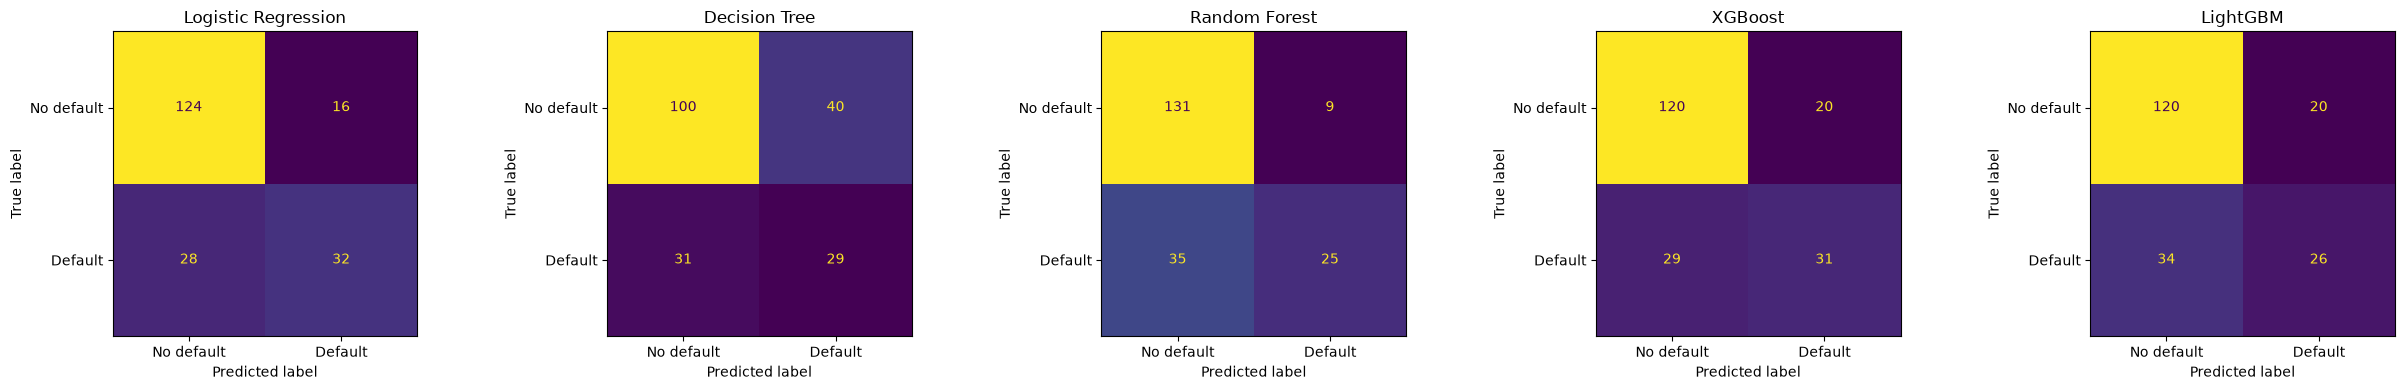

In [15]:
plot_confusion(baseline, "figures/cm_baseline.png")

The bottom-left cell of each matrix is the number of defaulters the model missed (false negatives). Logistic Regression has the best baseline recall at about 0.53 (XGBoost is next at 0.52), so even the best model lets almost half of the defaulters through.

## 8. Fixing the class imbalance

With `class_weight="balanced"` each class gets a weight inversely proportional to how often it appears, so a mistake on a defaulter costs about 2.3 times more than a mistake on a good applicant during training.

In [16]:
balanced = train(class_weight="balanced")#sets each class weight to w_c = n/{k dot n_c} (n = number of rows,k = number of classes (2), n_c = number of rows in class c).
bal_table = metrics(balanced)
bal_table

,Accuracy,Precision,Recall,Specificity,F1
Logistic Regression,0.750,0.558,0.800,0.729,0.658
Decision Tree,0.570,0.377,0.667,0.529,0.482
Random Forest,0.770,0.617,0.617,0.836,0.617
XGBoost,0.740,0.569,0.550,0.821,0.559
LightGBM,0.715,0.525,0.533,0.793,0.529


## Why recall matters more here?
Recall = defaulters caught / all real defaulters. A missed defaulter (false negative) means the bank lends money it doesn't get back. That costs far more than rejecting a good applicant

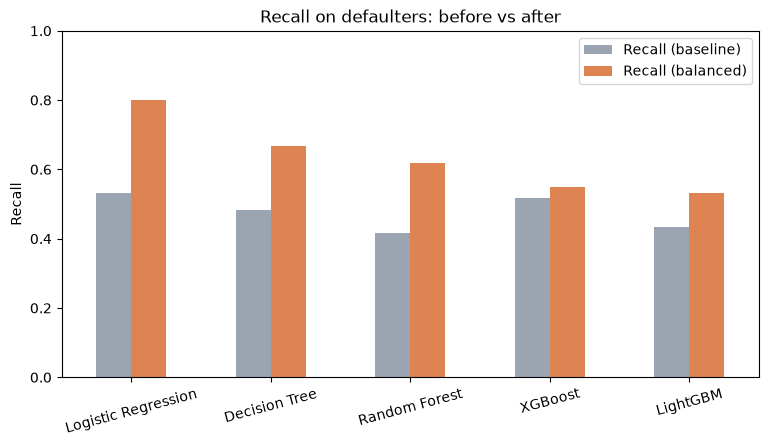

,Recall (baseline),Recall (balanced)
Logistic Regression,0.533,0.800
Decision Tree,0.483,0.667
Random Forest,0.417,0.617
XGBoost,0.517,0.550
LightGBM,0.433,0.533


In [17]:
compare = pd.DataFrame({"Recall (baseline)": base_table["Recall"],
                        "Recall (balanced)": bal_table["Recall"]})
compare.plot(kind="bar", rot=15, figsize=(9, 4.5), color=["#9AA5B1", "#DD8452"])
plt.title("Recall on defaulters: before vs after")
plt.ylabel("Recall")
plt.ylim(0, 1)
plt.savefig("figures/recall_compare.png", dpi=150, bbox_inches="tight")
plt.show()
compare
#recall compares the costly mistake only since defaulters matter more here

Recall goes up for all five models. Logistic Regression goes from 0.53 to 0.80 and keeps the best F1. The price is specificity and precision: the model now rejects more good applicants (specificity drops from 0.89 to 0.73), which is the trade we want in lending. The Decision Tree gains recall but loses a lot of accuracy, so it ends up the weakest model. The boosting models gain the least: XGBoost only moves from 0.52 to 0.55, and LightGBM from 0.43 to 0.53.

## 9. Is this just a lucky split?

One 80/20 split is only 60 defaulters in the test set. We repeat the balanced training with 5-fold stratified cross-validation on all 1000 rows to check that the numbers hold. We also record ROC-AUC, which section 11 explains.

In [18]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)# 5 folds 
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall",
           "specificity": make_scorer(recall_score, pos_label=0), "f1": "f1",
           "roc_auc": "roc_auc"}#specificity is number of good applicants approved
#scoring maps names to scorers
rows = {}
for name, pipe in make_models("balanced").items():
    scores = cross_validate(pipe, X, y, cv=cv, scoring=scoring)#pass the pipeline and all features,all labels
    rows[name] = {m: f"{scores['test_' + m].mean():.3f} ± {scores['test_' + m].std():.3f}"
                  for m in scoring}#pipeline is refit for each fold so no leakage
cv_table = pd.DataFrame(rows).T
cv_table

,accuracy,precision,recall,specificity,f1,roc_auc
Logistic Regression,0.719 ± 0.027,0.524 ± 0.034,0.720 ± 0.041,0.719 ± 0.029,0.606 ± 0.034,0.786 ± 0.019
Decision Tree,0.636 ± 0.037,0.435 ± 0.029,0.660 ± 0.077,0.626 ± 0.080,0.520 ± 0.021,0.670 ± 0.025
Random Forest,0.735 ± 0.012,0.561 ± 0.022,0.547 ± 0.016,0.816 ± 0.018,0.553 ± 0.014,0.778 ± 0.027
XGBoost,0.753 ± 0.013,0.596 ± 0.022,0.550 ± 0.039,0.840 ± 0.013,0.571 ± 0.028,0.766 ± 0.016
LightGBM,0.730 ± 0.019,0.553 ± 0.036,0.543 ± 0.031,0.810 ± 0.032,0.547 ± 0.021,0.776 ± 0.026


## 10. Hyperparameter tuning

So far every model used default settings, apart from the depth limit on the tree. `GridSearchCV` tries every combination in a small grid with 5-fold cross-validation and keeps the best one. 

In [19]:
grids = {
    "Logistic Regression": {"clf__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10]},  # C = inverse regularisation strength
    "Decision Tree": {"clf__max_depth": [2, 3, 4, 5, 7, None], "clf__min_samples_leaf": [1, 5, 10, 20]},
    "Random Forest": {"clf__n_estimators": [200, 500], "clf__max_depth": [4, 6, 10, None],
                      "clf__min_samples_leaf": [1, 3, 5, 10], "clf__max_features": ["sqrt", 0.3]},
    "XGBoost": {"clf__n_estimators": [100, 300], "clf__max_depth": [2, 3, 5],
                "clf__learning_rate": [0.03, 0.1], "clf__subsample": [0.8, 1.0]},
    "LightGBM": {"clf__n_estimators": [100, 300], "clf__num_leaves": [4, 8, 16],
                 "clf__learning_rate": [0.03, 0.1], "clf__min_child_samples": [10, 30]},
}

tuned, best = {}, {}
for name, pipe in make_models("balanced").items():
    gs = GridSearchCV(pipe, grids[name], scoring="f1", cv=cv, n_jobs=-1).fit(X_train, y_train)
    tuned[name] = gs.best_estimator_
    best[name] = {"Best parameters": {k.replace("clf__", ""): v for k, v in gs.best_params_.items()},
                  "CV F1 on train": round(gs.best_score_, 3)}
pd.set_option("display.max_colwidth", None)
pd.DataFrame(best).T

,Best parameters,CV F1 on train
Logistic Regression,{'C': 0.03},0.604
Decision Tree,"{'max_depth': 5, 'min_samples_leaf': 1}",0.562
Random Forest,"{'max_depth': 10, 'max_features': 0.3, 'min_samples_leaf': 5, 'n_estimators': 200}",0.617
XGBoost,"{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100, 'subsample': 0.8}",0.609
LightGBM,"{'learning_rate': 0.03, 'min_child_samples': 10, 'n_estimators': 100, 'num_leaves': 8}",0.629


In [20]:
pd.concat({"Default settings": bal_table, "Tuned": metrics(tuned)})

Accuracy  Precision  Recall  \
Default settings Logistic Regression     0.750      0.558   0.800   
                 Decision Tree           0.570      0.377   0.667   
                 Random Forest           0.770      0.617   0.617   
                 XGBoost                 0.740      0.569   0.550   
                 LightGBM                0.715      0.525   0.533   
Tuned            Logistic Regression     0.720      0.522   0.800   
                 Decision Tree           0.570      0.377   0.667   
                 Random Forest           0.710      0.512   0.717   
                 XGBoost                 0.750      0.568   0.700   
                 LightGBM                0.685      0.482   0.683   

                                      Specificity     F1  
Default settings Logistic Regression        0.729  0.658  
                 Decision Tree              0.529  0.482  
                 Random Forest              0.836  0.617  
                 XGBoost                    0.821  0.559  
                 LightGBM                   0.793  0.529  
Tuned            Logistic Regression        0.686  0.632  
                 Decision Tree              0.529  0.482  
                 Random Forest              0.707  0.597  
                 XGBoost                    0.771  0.627  
                 LightGBM                   0.686  0.566

## 11. ROC curve and AUC

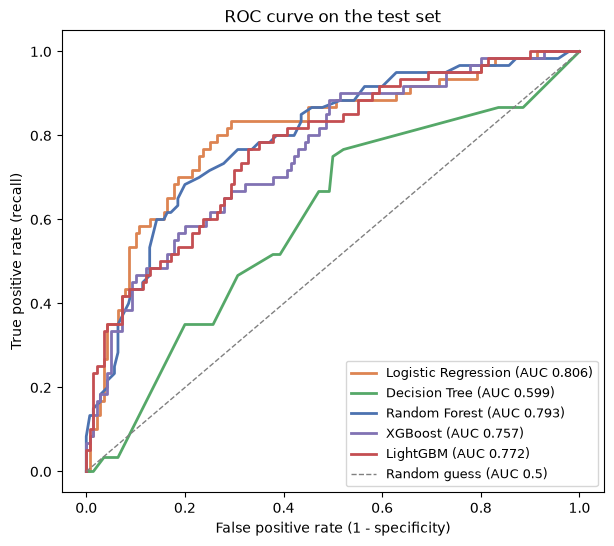

In [21]:
colors = {"Logistic Regression": "#DD8452", "Decision Tree": "#55A868", "Random Forest": "#4C72B0",
          "XGBoost": "#8172B3", "LightGBM": "#C44E52"}
fig, ax = plt.subplots(figsize=(7, 6))
for name, m in balanced.items():
    proba = m.predict_proba(X_test)[:, 1]          # column 1 = P(default)
    fpr, tpr, _ = roc_curve(y_test, proba)
    ax.plot(fpr, tpr, lw=2, color=colors[name], label=f"{name} (AUC {roc_auc_score(y_test, proba):.3f})")
ax.plot([0, 1], [0, 1], "--", color="grey", lw=1, label="Random guess (AUC 0.5)")
ax.set_xlabel("False positive rate (1 - specificity)")
ax.set_ylabel("True positive rate (recall)")
ax.set_title("ROC curve on the test set")
ax.legend(loc="lower right", fontsize=9)
plt.savefig("figures/roc.png", dpi=150, bbox_inches="tight")
plt.show()

Logistic Regression has the highest curve and the best AUC (0.81). Random Forest (0.79), LightGBM (0.77) and XGBoost (0.76) are close behind, and the Decision Tree (0.60) is close to a random guess. Because AUC does not depend on the threshold, this confirms that Logistic Regression ranks applicants best, not only that it suits the 0.5 cut-off.

## 12. Final model

Balanced Logistic Regression has the highest recall and F1, and it is also the easiest to explain: every feature gets one weight, and a positive weight pushes the applicant towards default. In lending that matters, since a bank has to be able to say why an application was rejected.

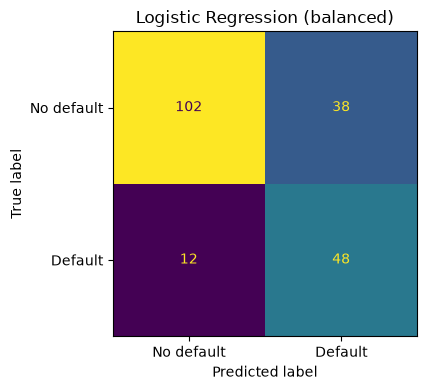

In [22]:
final = balanced["Logistic Regression"]
plot_confusion({"Logistic Regression (balanced)": final}, "figures/cm_final.png")

### check feature importance and weights assigned to them

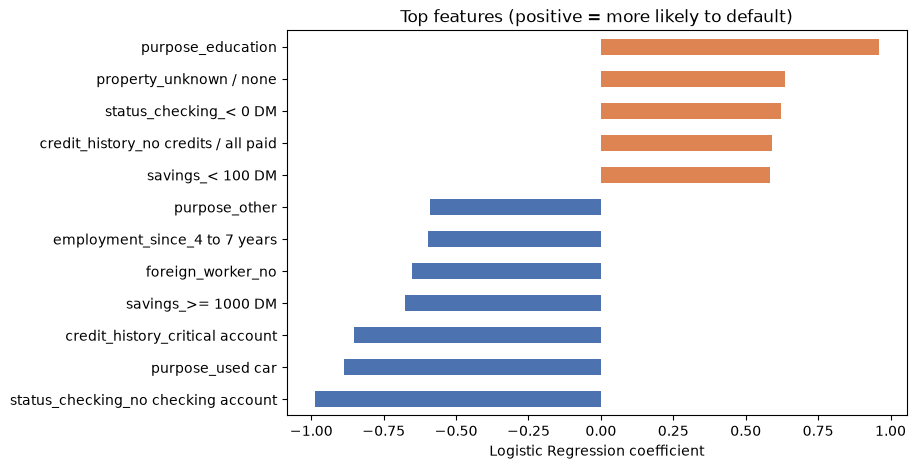

In [23]:
names = final.named_steps["prep"].get_feature_names_out()#returns names of features
names = [n.split("__", 1)[1] for n in names]#remove num__ cat__ prefix
coef = pd.Series(final.named_steps["clf"].coef_[0], index=names)#learned weights
top = coef.reindex(coef.abs().sort_values(ascending=False).index[:12]).sort_values()#select 12 largest weights by size

top.plot(kind="barh", color=["#4C72B0" if v < 0 else "#DD8452" for v in top], figsize=(8, 5))
plt.title("Top features (positive = more likely to default)")
plt.xlabel("Logistic Regression coefficient")
plt.savefig("figures/top_features.png", dpi=150, bbox_inches="tight")
plt.show()

blue means lower risk feature and red=higher risk and more likely to default

## 13. Predict a new applicant

We start from a typical applicant (median for numeric columns, most common value for categorical ones) and change a few fields to see how the final model scores them.

In [24]:
defaults = {c: (X_train[c].median() if c in num_cols else X_train[c].mode()[0]) for c in X.columns}

In [25]:
applicant = pd.DataFrame([defaults])[X.columns]
applicant["credit_amount"] = 9000
applicant["duration_months"] = 36
applicant["status_checking"] = "< 0 DM"

for name, m in balanced.items():
    p = m.predict_proba(applicant)[0, 1]
    print(f"{name}: {p:.0%} default risk -> {'DEFAULT' if p >= 0.5 else 'OK'}")

Logistic Regression: 81% default risk -> DEFAULT
Decision Tree: 83% default risk -> DEFAULT
Random Forest: 82% default risk -> DEFAULT
XGBoost: 94% default risk -> DEFAULT
LightGBM: 95% default risk -> DEFAULT
